In [ ]:
from sklearn.ensemble import RandomForestClassifier as RF
import pandas as pd
import spacy as sc
link="S:\\ML\\Kaggle_dataset\\combined_sms_spam_ham.csv"
data_set=pd.read_csv(link)
data_set.head

,text,category,spam_ham_label,source,language
0,[PROMO] Beli paket Flash mulai 1GB di MY TELKO...,promo,spam,agtbaskara/dataset_sms_spam_v2,id
1,2.5 GB/30 hari hanya Rp 35 Ribu Spesial buat A...,promo,spam,agtbaskara/dataset_sms_spam_v2,id
2,"2016-07-08 11:47:11.Plg Yth, sisa kuota Flash ...",promo,spam,agtbaskara/dataset_sms_spam_v2,id
3,"2016-08-07 11:29:47.Plg Yth, sisa kuota Flash ...",promo,spam,agtbaskara/dataset_sms_spam_v2,id
4,4.5GB/30 hari hanya Rp 55 Ribu Spesial buat an...,promo,spam,agtbaskara/dataset_sms_spam_v2,id


In [3]:
nlp=sc.load("en_core_web_sm")
def preprocessing(text):
    low=nlp(text.lower())
    tokens=[]

    for i in low:
        if i.is_stop :
            continue
        if i.is_space:
            continue
        if i.is_punct:
            continue
        tokens.append(i.lemma_)
        
    return " ".join(tokens) 

In [4]:
data_set["new_text"]=data_set["text"].apply(preprocessing)

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer as tvc
from sklearn.model_selection import train_test_split as ttp
from scipy.sparse import hstack as stk
vectorize=tvc()
vec_text=vectorize.fit_transform(data_set["new_text"])
features=pd.get_dummies(data_set["category"])
x=stk([vec_text,features.values])
y=data_set["spam_ham_label"]

In [ ]:
x_train,x_test,y_train,y_test=ttp(x,y,train_size=0.7,random_state=8,shuffle=True)
model=RF()
model.fit(x_train,y_train)
import joblib
joblib.dump(model,'rfNlp.joblib')

['rfNlp.joblib']

In [8]:
mymodel=joblib.load('rfNlp.joblib')

Accuracy Score 97.94


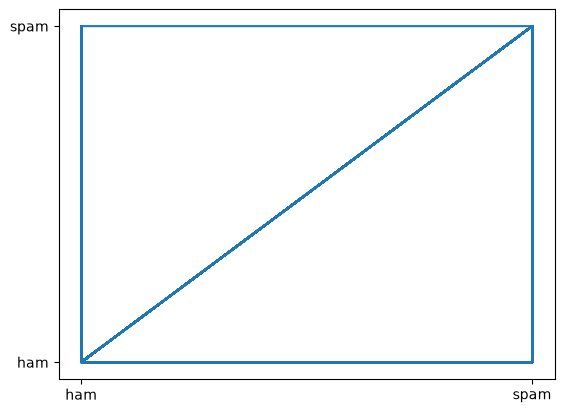

In [9]:
from sklearn.metrics import accuracy_score as ass
preds=mymodel.predict(x_test)
score=ass(y_test,preds)
accu =score*100
print("Accuracy Score",round(accu,2))
import matplotlib.pyplot as mpl
mpl.plot(y_test,preds)
mpl.show()